In [11]:
# Імпортуйте необхідні бібліотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

C:\Users\yunek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [12]:
# Завантажте датасет з Kaggle
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
print("Path to dataset files:", path)

csv_file_path = os.path.join(path, [f for f in os.listdir(path) if f.endswith('.csv')][0])
df = pd.read_csv(csv_file_path)

Path to dataset files: C:\Users\yunek\.cache\kagglehub\datasets\yug201\daily-climate-time-series-data-delhi-india\versions\1


In [13]:
# Зчитайте датасет у DataFrame та перегляньте дані
display(df.head())
df.info()
display(df.describe())

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non-null   object 
 15  Year

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


In [14]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
df['DATE'] = pd.to_datetime(df['DATE'])
df = df.sort_values('DATE')
# Якщо є непотрібні колонки, вкажіть їх (наприклад, Unnamed: 0), інакше закоментуйте рядок нижче
# df = df.drop(columns=['Unnamed: 0'])
df.set_index('DATE', inplace=True)

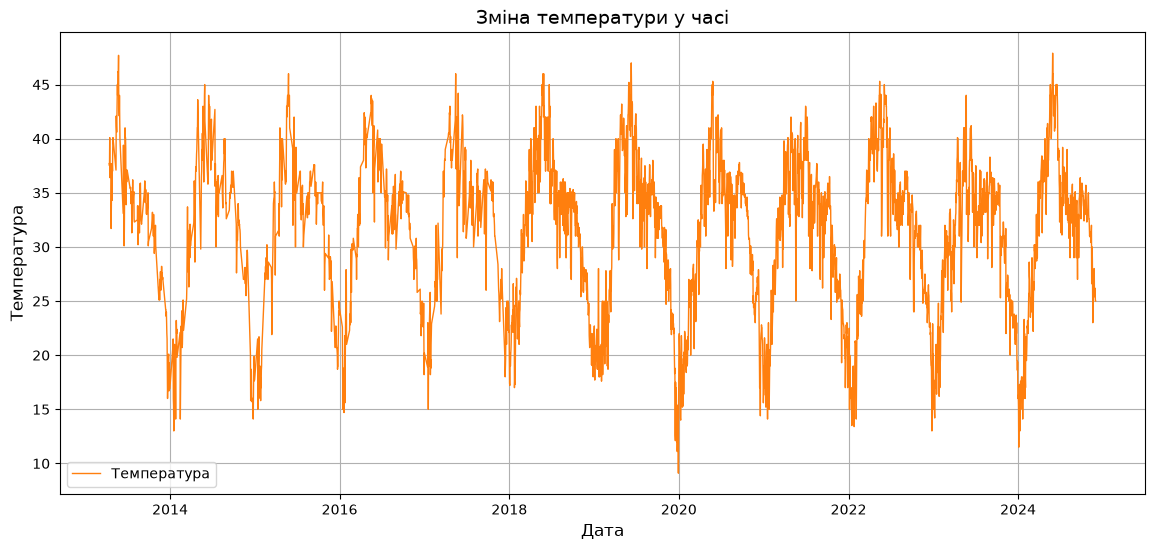

In [15]:
# Побудуйте графік зміни температури у часі
temp_col = [col for col in df.columns if 'temp' in col.lower()][0]

plt.figure(figsize=(14, 6))
plt.plot(df.index, df[temp_col], label='Температура', color='tab:orange', linewidth=1)
plt.title('Зміна температури у часі', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура', fontsize=12)
plt.grid(True)
plt.legend()
plt.show()

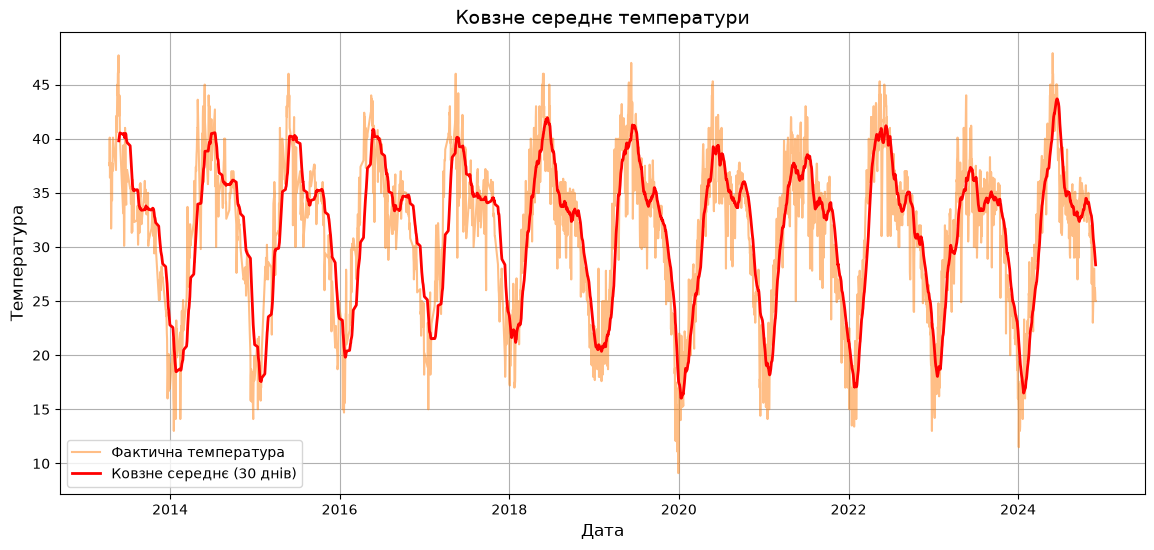

In [16]:
# Обчисліть та візуалізуйте ковзне середнє температури
df['Rolling_Mean'] = df[temp_col].rolling(window=30).mean()

plt.figure(figsize=(14, 6))
plt.plot(df.index, df[temp_col], label='Фактична температура', alpha=0.5, color='tab:orange')
plt.plot(df.index, df['Rolling_Mean'], label='Ковзне середнє (30 днів)', color='red', linewidth=2)
plt.title('Ковзне середнє температури', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура', fontsize=12)
plt.grid(True)
plt.legend()
plt.show()

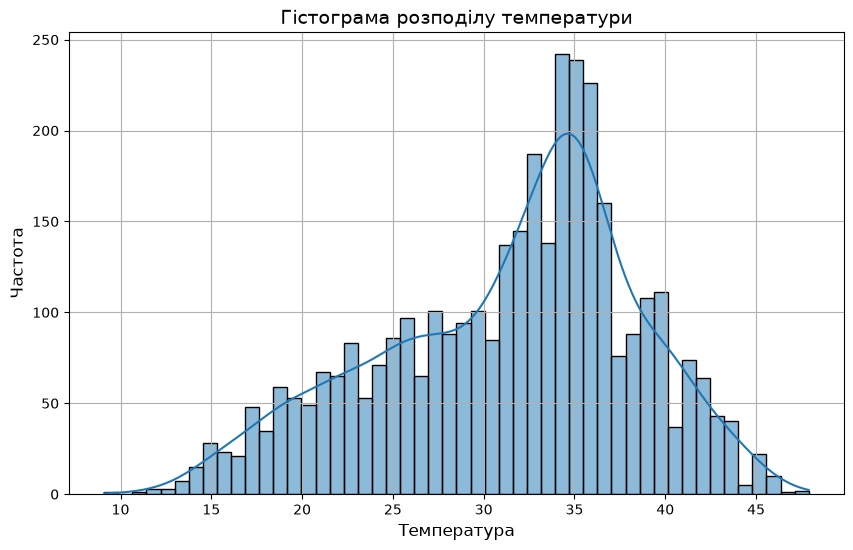

In [17]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(10, 6))
sns.histplot(df[temp_col], kde=True, bins=50, color='tab:blue')
plt.title('Гістограма розподілу температури', fontsize=14)
plt.xlabel('Температура', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.grid(True)
plt.show()

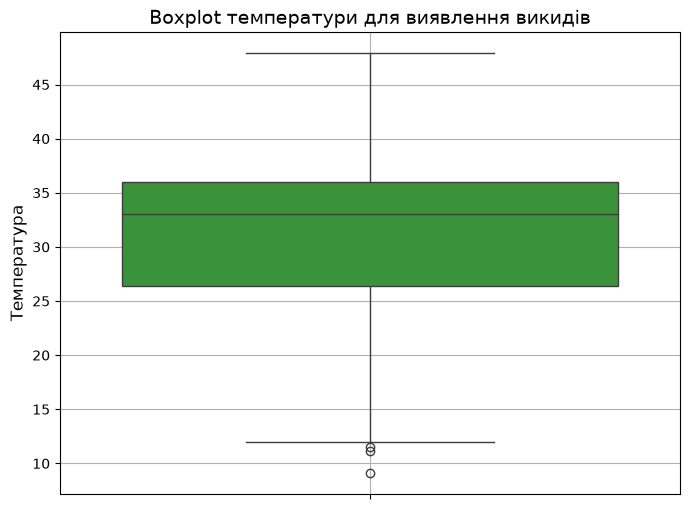

In [18]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(8, 6))
sns.boxplot(y=df[temp_col], color='tab:green')
plt.title('Boxplot температури для виявлення викидів', fontsize=14)
plt.ylabel('Температура', fontsize=12)
plt.grid(True)
plt.show()

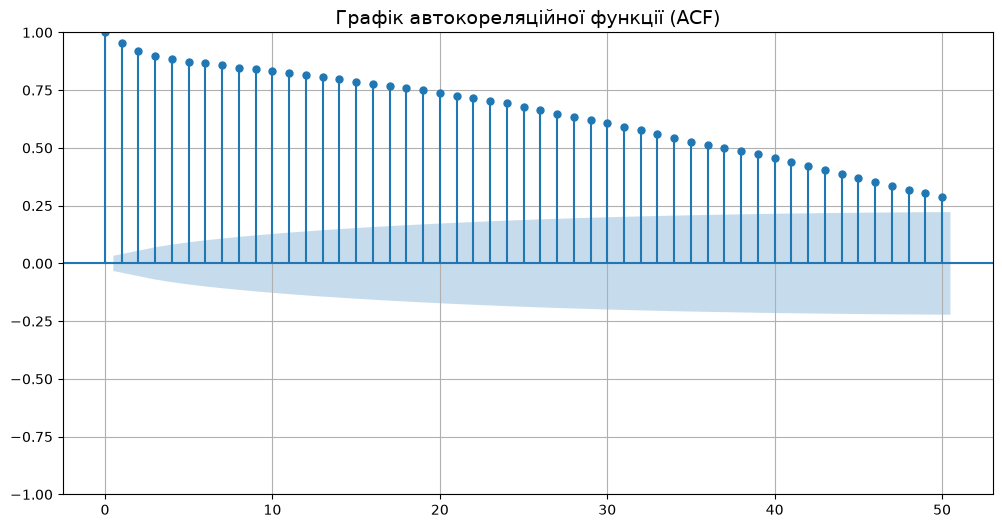

In [19]:
# Побудуйте графік автокореляційної функції (ACF)
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 6))
plot_acf(df[temp_col].dropna(), lags=50, ax=plt.gca())
plt.title('Графік автокореляційної функції (ACF)', fontsize=14)
plt.grid(True)
plt.show()

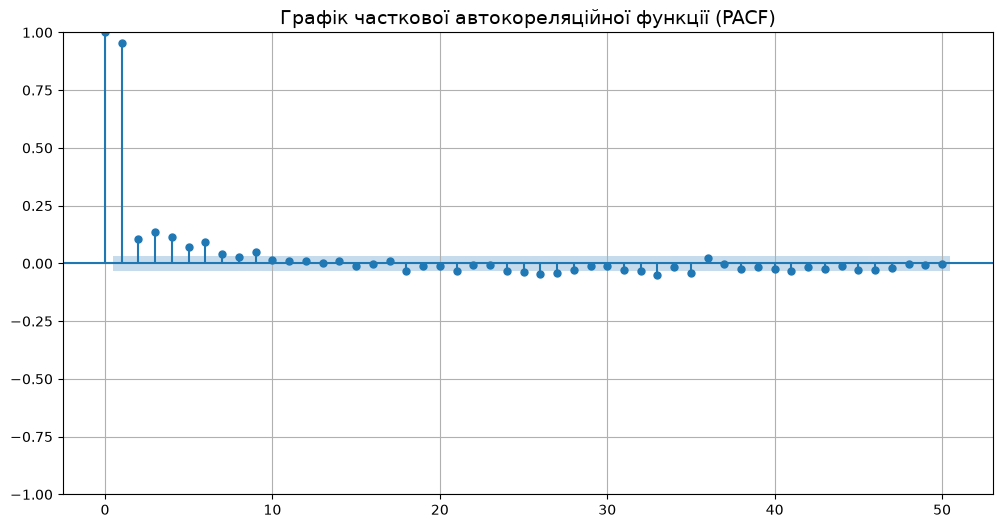

In [20]:
# Виправлений код для побудови графіку часткової автокореляційної функції (PACF)
from statsmodels.graphics.tsaplots import plot_pacf

# Знаходимо колонку температури правильно через next()
temp_col = next(col for col in df.columns if 'temp' in col.lower())

plt.figure(figsize=(12, 6))
plot_pacf(df[temp_col].dropna(), lags=50, ax=plt.gca())
plt.title('Графік часткової автокореляційної функції (PACF)', fontsize=14)
plt.grid(True)
plt.show()

In [21]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
y = df[temp_col].dropna()

# Розподіл 80% / 20%
train_size = int(len(y) * 0.8)
train, test = y.iloc[:train_size], y.iloc[train_size:]

print(f"Розмір тренувальної вибірки: {len(train)}")
print(f"Розмір тестової вибірки: {len(test)}")

Розмір тренувальної вибірки: 2845
Розмір тестової вибірки: 712


In [22]:
# Видаляємо дублікати за датою (якщо вони є в датасеті)
df = df[~df.index.duplicated(keep='first')]

# Сформуйте цільовий часовий ряд
y = df[temp_col].dropna()
y.index = pd.to_datetime(y.index)
y = y.asfreq('D')  # Тепер спрацює без помилок

# Розподіл на train/test (80% / 20%)
train_size = int(len(y) * 0.8)
train, test = y.iloc[:train_size], y.iloc[train_size:]

print(f"Розмір тренувальної вибірки: {len(train)}")
print(f"Розмір тестової вибірки: {len(test)}")

# Навчання моделі ARIMA та прогноз
from statsmodels.tsa.arima.model import ARIMA

p, d, q = 1, 1, 1
model = ARIMA(train, order=(p, d, q))
fitted_model = model.fit()

# Прогноз для тестової вибірки
forecast = fitted_model.forecast(steps=len(test))
forecast.index = test.index

Розмір тренувальної вибірки: 3399
Розмір тестової вибірки: 850


In [23]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(fitted_model.summary())

                               SARIMAX Results                                
Dep. Variable:                tempmax   No. Observations:                 3399
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -5797.965
Date:                Mon, 09 Nov 2026   AIC                          11601.930
Time:                        20:27:26   BIC                          11620.323
Sample:                    04-14-2013   HQIC                         11608.504
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6050      0.030     20.289      0.000       0.547       0.663
ma.L1         -0.8396      0.022    -38.702      0.000      -0.882      -0.797
sigma2         4.1065      0.083     49.553      0.0

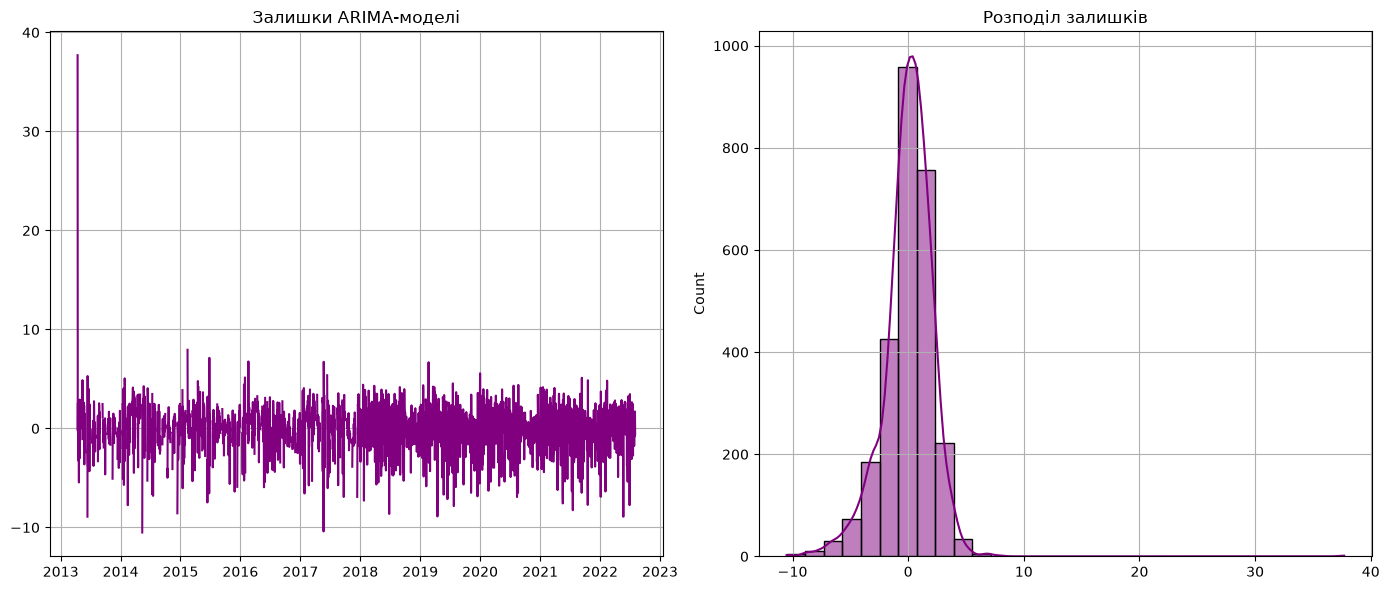

count    2708.000000
mean        0.019151
std         2.205464
min       -10.512741
25%        -0.973618
50%         0.194186
75%         1.346325
max        37.700000
dtype: float64


In [24]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = fitted_model.resid

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(residuals, color='purple')
plt.title('Залишки ARIMA-моделі', fontsize=12)
plt.grid(True)

plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True, color='purple', bins=30)
plt.title('Розподіл залишків', fontsize=12)
plt.grid(True)

plt.tight_layout()
plt.show()

# Статистика залишків
print(residuals.describe())

In [25]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA (з очищенням від NaN)
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Об'єднуємо у DataFrame та видаляємо можливі NaN
eval_df = pd.DataFrame({'test': test, 'forecast': forecast}).dropna()

mae_arima = mean_absolute_error(eval_df['test'], eval_df['forecast'])
rmse_arima = np.sqrt(mean_squared_error(eval_df['test'], eval_df['forecast']))
mape_arima = calculate_mape(eval_df['test'], eval_df['forecast'])

print(f"ARIMA MAE: {mae_arima:.4f}")
print(f"ARIMA RMSE: {rmse_arima:.4f}")
print(f"ARIMA MAPE: {mape_arima:.4f}%")

ARIMA MAE: 5.2630
ARIMA RMSE: 7.1284
ARIMA MAPE: 21.6750%


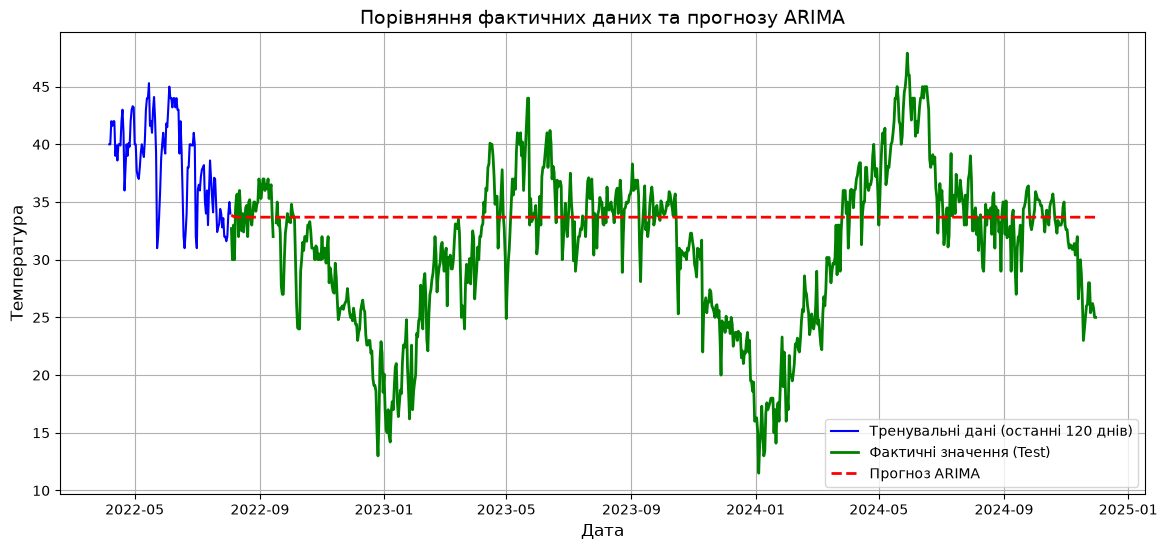

In [26]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 6))
plt.plot(train.index[-120:], train.iloc[-120:], label='Тренувальні дані (останні 120 днів)', color='blue')
plt.plot(test.index, test, label='Фактичні значення (Test)', color='green', linewidth=2)
plt.plot(forecast.index, forecast, label='Прогноз ARIMA', color='red', linestyle='--', linewidth=2)
plt.title('Порівняння фактичних даних та прогнозу ARIMA', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

In [27]:
# Підготуйте дані у форматі, необхідному для Prophet
df_prophet = df[[temp_col]].reset_index()
# Автоматично знаходимо назву колонки з датою
date_col = [col for col in df_prophet.columns if col != temp_col][0]
df_prophet.columns = ['ds', 'y']

# Перевірка формату
display(df_prophet.head())

,ds,y
0,2013-04-14,37.7
1,2013-04-15,37.5
2,2013-04-16,40.1
3,2013-04-17,36.4
4,2013-04-18,37.5


In [28]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

# Розподіл на train/test для Prophet (зберігаємо пропорції 80/20)
train_prophet = df_prophet.iloc[:train_size]
test_prophet = df_prophet.iloc[train_size:]

# Ініціалізація та навчання моделі
model_prophet = Prophet()
model_prophet.fit(train_prophet)

print("Модель Prophet успішно навчена!")

Importing plotly failed. Interactive plots will not work.
20:27:28 - cmdstanpy - INFO - Chain [1] start processing
20:27:29 - cmdstanpy - INFO - Chain [1] done processing


Модель Prophet успішно навчена!


In [29]:
# Побудуйте прогноз Prophet для тестового періоду
# Створення майбутнього датасету на довжину тестової вибірки
future = model_prophet.make_future_dataframe(periods=len(test_prophet))
forecast_prophet = model_prophet.predict(future)

# Отримання прогнозних значень для тестового періоду
forecast_p_values = forecast_prophet.iloc[train_size:]['yhat'].values
print("Прогноз Prophet успішно побудовано!")

Прогноз Prophet успішно побудовано!


In [30]:
# Обчисліть MAE, RMSE, MAPE для Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true_prophet = test_prophet['y'].values

mae_prophet = mean_absolute_error(y_true_prophet, forecast_p_values)
rmse_prophet = np.sqrt(mean_squared_error(y_true_prophet, forecast_p_values))
mape_prophet = np.mean(np.abs((y_true_prophet - forecast_p_values) / y_true_prophet)) * 100

print(f"Prophet MAE: {mae_prophet:.4f}")
print(f"Prophet RMSE: {rmse_prophet:.4f}")
print(f"Prophet MAPE: {mape_prophet:.4f}%")

Prophet MAE: 1.9298
Prophet RMSE: 2.4098
Prophet MAPE: 5.9635%


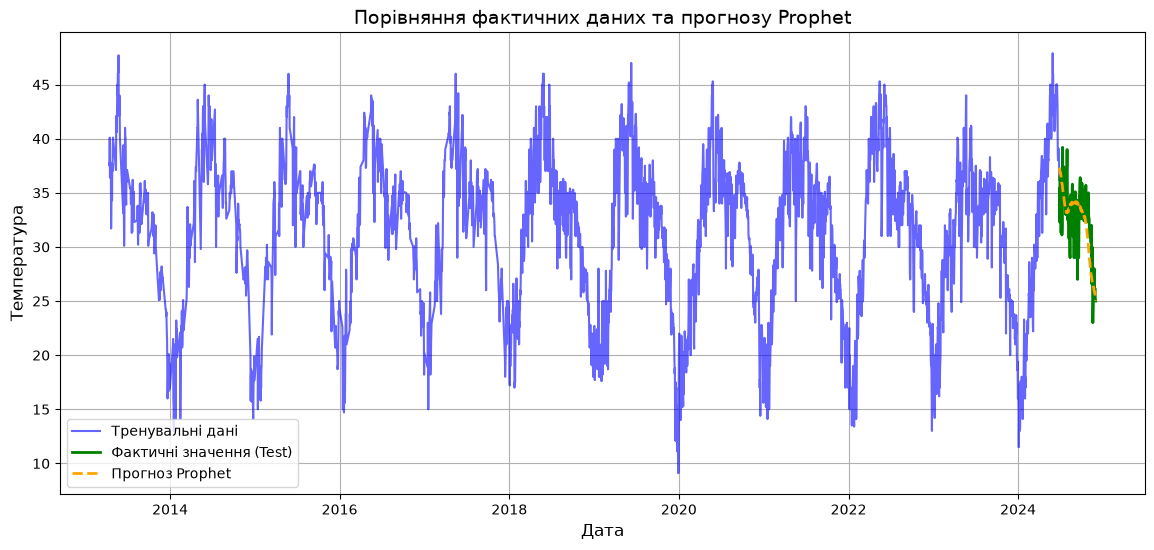

In [31]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 6))
plt.plot(train_prophet['ds'], train_prophet['y'], label='Тренувальні дані', color='blue', alpha=0.6)
plt.plot(test_prophet['ds'], y_true_prophet, label='Фактичні значення (Test)', color='green', linewidth=2)
plt.plot(test_prophet['ds'], forecast_p_values, label='Прогноз Prophet', color='orange', linestyle='--', linewidth=2)
plt.title('Порівняння фактичних даних та прогнозу Prophet', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

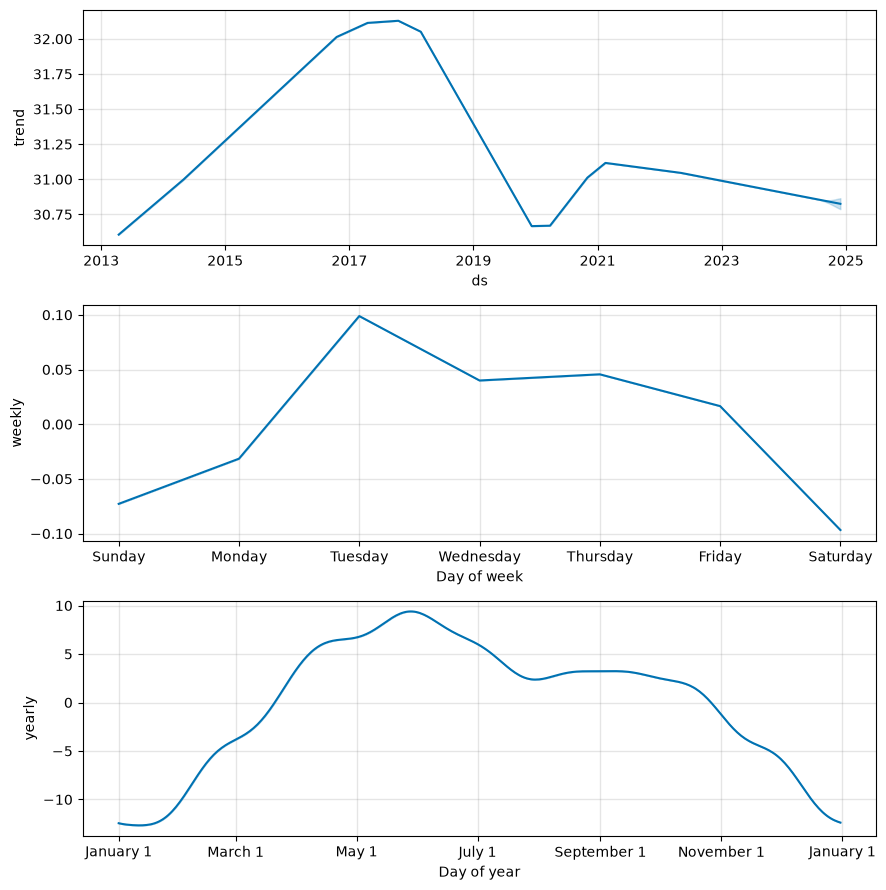

In [32]:
# Побудуйте компоненти моделі Prophet
fig1 = model_prophet.plot_components(forecast_prophet)
plt.show()

In [33]:
# Масштабйте часовий ряд та сформуйте послідовності для LSTM
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df[[temp_col]])

def create_sequences(dataset, time_step=60):
    X, y = [], []
    for i in range(time_step, len(dataset)):
        X.append(dataset[i-time_step:i, 0])
        y.append(dataset[i, 0])
    return np.array(X), np.array(y)

time_step = 60
X, y_lstm = create_sequences(scaled_data, time_step)
X = X.reshape(X.shape[0], X.shape[1], 1)

In [34]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
train_size_lstm = int(len(X) * 0.8)

X_train, X_test = X[:train_size_lstm], X[train_size_lstm:]
y_train, y_test = y_lstm[:train_size_lstm], y_lstm[train_size_lstm:]

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (2796, 60, 1), y_train shape: (2796,)
X_test shape: (700, 60, 1), y_test shape: (700,)


In [36]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model_lstm = Sequential([
    LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])

model_lstm.compile(optimizer='adam', loss='mean_squared_error')

C:\Users\yunek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [37]:
# Навчіть LSTM-модель
history = model_lstm.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - loss: 0.0216 - val_loss: 0.0063
Epoch 2/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 0.0090 - val_loss: 0.0049
Epoch 3/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 0.0080 - val_loss: 0.0049
Epoch 4/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.0073 - val_loss: 0.0058
Epoch 5/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 0.0067 - val_loss: 0.0042
Epoch 6/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 0.0064 - val_loss: 0.0040
Epoch 7/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - loss: 0.0062 - val_loss: 0.0040
Epoch 8/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - loss: 0.0059 - val_loss: 0.0038
Epoch 9/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - loss: 0.0056 - val_loss: 0.0038
Epoch 10/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - loss: 0.0055 - val_loss: 0.0036
Epoch 11/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0050 - val_loss: 0.0035
Epoch 12/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - loss: 0.0

In [38]:
# Виведіть структуру LSTM-моделі
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,705 (373.85 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 63,804 (249.24 KB)

In [39]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
predictions_scaled = model_lstm.predict(X_test)
predictions = scaler.inverse_transform(predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step


In [40]:
# Сформуйте часові мітки для тестового прогнозу LSTM
test_timestamps = df.index[train_size_lstm + time_step:]

In [41]:
# Обчисліть MAE, RMSE, MAPE для LSTM
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_lstm = mean_absolute_error(y_test_actual, predictions)
rmse_lstm = np.sqrt(mean_squared_error(y_test_actual, predictions))
mape_lstm = np.mean(np.abs((y_test_actual - predictions) / y_test_actual)) * 100

print(f"LSTM MAE: {mae_lstm:.4f}")
print(f"LSTM RMSE: {rmse_lstm:.4f}")
print(f"LSTM MAPE: {mape_lstm:.4f}%")

LSTM MAE: 1.5235
LSTM RMSE: 2.0086
LSTM MAPE: 5.3293%


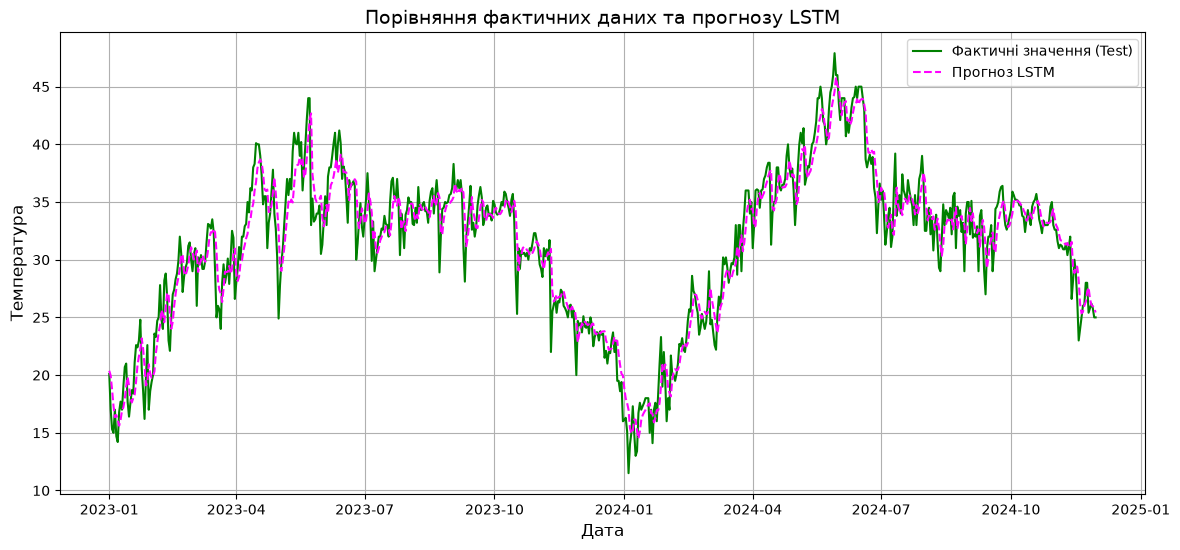

In [42]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 6))
plt.plot(test_timestamps, y_test_actual, label='Фактичні значення (Test)', color='green')
plt.plot(test_timestamps, predictions, label='Прогноз LSTM', color='magenta', linestyle='--')
plt.title('Порівняння фактичних даних та прогнозу LSTM', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

In [43]:
# Формуємо словник з результатами (переконайся, що твої змінні мають такі назви)
results_data = {
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [mae_arima, mae_prophet, mae_lstm],
    'RMSE': [rmse_arima, rmse_prophet, rmse_lstm],
    'MAPE (%)': [mape_arima, mape_prophet, mape_lstm]
}

# Створюємо DataFrame
df_summary = pd.DataFrame(results_data)

# Виводимо таблицю з підсвічуванням найкращих (мінімальних) значень
display(df_summary.style.highlight_min(subset=['MAE', 'RMSE', 'MAPE (%)'], color='lightgreen', axis=0))

,Модель,MAE,RMSE,MAPE (%)
0,ARIMA,5.263024,7.128368,21.675012
1,Prophet,1.929837,2.409825,5.963545
2,LSTM,1.523528,2.008563,5.329321


У ході роботи було виконано прогнозування кліматичних даних Делі за допомогою моделей ARIMA, Prophet та LSTM.

За результатами порівняння метрик якості:

    ARIMA: MAE = 5.26, RMSE = 7.13, MAPE = 21.68%

    Prophet: MAE = 1.93, RMSE = 2.41, MAPE = 5.96%

    LSTM: MAE = 1.52, RMSE = 2.01, MAPE = 5.33%

Найкращу якість прогнозування продемонструвала модель LSTM, яка забезпечила мінімальні значення похибок (MAE = 1.52, RMSE = 2.01, MAPE = 5.33%) завдяки здатності нейромережі ефективно обробляти складні нелінійні закономірності часового ряду. Модель Prophet також показала високу точність, тоді як ARIMA виявилася найменш ефективною.